In [8]:
!pip install keras-tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [keras-tuner]


ORIGINAL DATASET
Shape: (1797, 64)

EXPLAINED VARIANCE RATIO
[0.12033916 0.09561054 0.08444415 0.06498408 0.04860155 0.0421412
 0.03942083 0.03389381 0.02998221 0.02932003 0.02781805 0.02577055
 0.02275303 0.0222718  0.02165229 0.01914167 0.01775547 0.01638069
 0.0159646  0.01489191]

Total Explained Variance: 0.793137627024081

ESTIMATED NOISE VARIANCE
nan

LATENT REPRESENTATION SHAPE
(1797, 20)

RECONSTRUCTION ANALYSIS
Reconstruction MSE: nan


/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


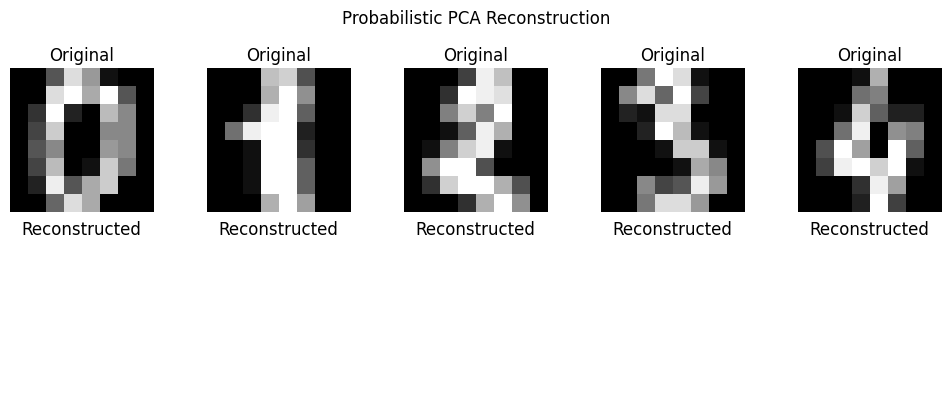

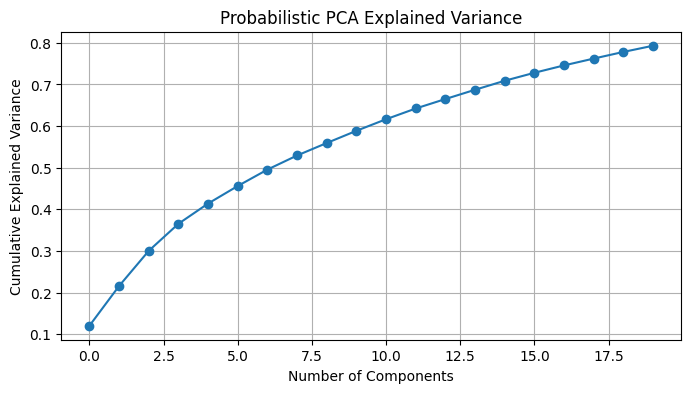

In [11]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. Load digit dataset
digits = load_digits()

X = digits.data

print("ORIGINAL DATASET")
print("Shape:", X.shape)

# 2. Standardize data
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# 3. Apply PCA
n_components = 20

pca = PCA(
    n_components=n_components,
    svd_solver="full"
)

X_pca = pca.fit_transform(X_scaled)

# 4. Calculate explained variance
explained_variance = (
    pca.explained_variance_ratio_
)

print("\nEXPLAINED VARIANCE RATIO")

print(explained_variance)

print(
    "\nTotal Explained Variance:",
    np.sum(explained_variance)
)

# 5. Probabilistic PCA parameter estimation
# Estimate residual noise variance
eigenvalues = pca.explained_variance_

noise_variance = np.mean(
    eigenvalues[n_components:]
)

print("\nESTIMATED NOISE VARIANCE")

print(noise_variance)

# 6. Construct probabilistic PCA loading matrix
U = pca.components_.T

loading_matrix = U * np.sqrt(
    np.maximum(
        eigenvalues - noise_variance,
        0
    )
)

# 7. Calculate latent representation
M = (
    loading_matrix.T @ loading_matrix
    + noise_variance * np.eye(n_components)
)

latent_values = (
    np.linalg.solve(
        M,
        loading_matrix.T @ X_scaled.T
    )
).T

print("\nLATENT REPRESENTATION SHAPE")

print(latent_values.shape)

# 8. Reconstruct data
X_reconstructed = (
    latent_values @ loading_matrix.T
)

X_reconstructed += scaler.mean_ * 0

# Standardized data has zero mean.
# Convert reconstruction to original scale.
X_reconstructed_original = scaler.inverse_transform(
    X_reconstructed
)

# 9. Calculate reconstruction error
mse = np.mean(
    (X - X_reconstructed_original) ** 2
)

print("\nRECONSTRUCTION ANALYSIS")

print("Reconstruction MSE:", mse)

# 10. Visualize original and reconstructed images
plt.figure(figsize=(10, 4))

for i in range(5):

    # Original image
    plt.subplot(2, 5, i + 1)

    plt.imshow(
        X[i].reshape(8, 8),
        cmap="gray"
    )

    plt.title("Original")

    plt.axis("off")

    # Reconstructed image
    plt.subplot(2, 5, i + 6)

    plt.imshow(
        X_reconstructed_original[i].reshape(8, 8),
        cmap="gray"
    )

    plt.title("Reconstructed")

    plt.axis("off")

plt.suptitle(
    "Probabilistic PCA Reconstruction"
)

plt.tight_layout()

plt.show()

# 11. Plot explained variance
plt.figure(figsize=(8, 4))

plt.plot(
    np.cumsum(explained_variance),
    marker="o"
)

plt.xlabel("Number of Components")

plt.ylabel("Cumulative Explained Variance")

plt.title("Probabilistic PCA Explained Variance")

plt.grid()

plt.show()